In [1]:
# Import packages

import numpy as np
from scipy.integrate import quad
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

In [2]:
# Define constants

c = 299792.458  # speed of light in km/s
f0 = 6.61e-9  # reference flux in erg/cm^2/s/Å for the B-band used by Perlmutter et al. 1999
H0 = 75.0  # Hubble constant in km/s/Mpc
cm_per_Mpc = 3.0857e24  # conversion factor for Mpc -> cm

In [3]:
# Read the supernovae data file

def load_data(filename):
    names = np.loadtxt(filename, usecols=0, dtype=str)
    z, m, dm = np.loadtxt(filename, usecols=(1, 2, 3), unpack=True)
    return names, z, m, dm

names, z, m, dm = load_data("sn_data.txt")

# Split the data into low-redshift and high-redshift supernovae

low = z < 0.11
high = z > 0.11

z_low, m_low, dm_low = z[low], m[low], dm[low]
z_high, m_high, dm_high = z[high], m[high], dm[high]

In [4]:
# Eq 8.13 - The Friedmann Equation

def E(z, OM, OL):
    a = 1/(1 + z)
    Ok = 1 - OM - OL
    return np.sqrt(abs(OM/a**3 + OL + Ok/a**2))  # outputs E(z) = H(z)/H0

In [5]:
# Eq 8.14 - The Comoving Distance, rc

def comoving_distance(z, H0, OM, OL):  # H0 is the Hubble constant in km s-1 Mpc-1
    z = np.atleast_1d(z)
    integral = np.array([quad(lambda zp: 1 / E(zp, OM, OL), 0, zi)[0] for zi in z])
    rc = (c / H0) * integral
    return rc  # outputs rc in Mpc

In [6]:
# The Luminosity Distance, dL

def luminosity_distance(z, H0, OM, OL):
    z = np.atleast_1d(z)
    rc = comoving_distance(z, H0, OM, OL)
    Ok = 1 - OM - OL
    if abs(Ok) < 1e-8:  # "flat", k = 0
        Sk = rc
    else:
        R0 = (c / H0) / np.sqrt(abs(Ok))
        if Ok < 0:  # OM + OL > 1, k = +1
            Sk = R0 * np.sin(rc / R0)
        else:  # OM + OL < 1, k = -1
            Sk = R0 * np.sinh(rc / R0)
    return (1 + z) * Sk  # outputs dL in Mpc
        
# For the milestone it can be assumed that the universe is "flat", i.e. k = 0

In [7]:
# Eq 8.16 - Chi-squared statistic

def chi2(f_obs, df_obs, f_model):
    return np.sum(((f_obs - f_model) / df_obs)**2)

def one_sigma_range(grid, chi2_values):
    chi2_values = np.array(chi2_values)
    within = grid[chi2_values <= chi2_values.min() + 1]
    return within.min(), within.max()

In [8]:
# Model magnitude using Eq 8.18 - effective flux and Eq  8.19 - effective magnitude

def model_magnitude(z, Lpeak, H0, OM, OL):
    dL = luminosity_distance(z, H0, OM, OL) * cm_per_Mpc  # convert Mpc -> cm
    f = Lpeak / (4.0 * np.pi * dL**2)
    return -2.5 * np.log10(f / f0)

# Model magnitude for z < 0.1 using the luminosity distance approximation

def model_magnitude_low(z, Lpeak):
    dL_approx = (1 + z ) * (c * z / H0) * cm_per_Mpc
    f = Lpeak / (4 * np.pi * dL_approx**2)
    return -2.5 * np.log10(f / f0)

In [9]:
# Chi-squared minimisation for Lpeak

# Define a grid of trial values for Lpeak using low-redshift supernovae (z < 0.1)
Lpeak_grid = np.linspace(1e39, 1e40, 1000)  # edited and updated to narrow-down the search window

# Compute chi-squared for each trial value of Lpeak
chi2_low_values = []
for L in Lpeak_grid:
    chi2_low_values.append(chi2(m_low, dm_low, model_magnitude_low(z_low, L)))

# Find the best-fit Lpeak
best_Lpeak = Lpeak_grid[np.argmin(chi2_low_values)]

L_low, L_high = one_sigma_range(Lpeak_grid, chi2_low_values)
L_err = (L_high - L_low) / 2
print(f"Lpeak = ({best_Lpeak:.3e} ± {L_err:.2e}) erg s⁻¹ Å⁻¹")

# --- L_peak fit (z < 0.1) ---
chi2_min_low = np.min(chi2_low_values)
dof_low = len(z_low) - 1                       # N points - 1 fitted parameter
crit_low = stats.chi2.ppf(0.95, dof_low)       # 5% significance critical value

print(f"χ²_min = {chi2_min_low:.2f}, DoF = {dof_low}, "
      f"reduced χ² = {chi2_min_low/dof_low:.2f}, critical (5%) = {crit_low:.2f}")

Lpeak = (3.261e+39 ± 1.35e+38) erg s⁻¹ Å⁻¹
χ²_min = 21.46, DoF = 17, reduced χ² = 1.26, critical (5%) = 27.59


In [10]:
# Chi-squared minimisation for Ω_Λ,0

# Define a grid of trial values for the dark energy density parameter, Ω_Λ,0 (OL)
OL_grid = np.linspace(0, 1, 1000)

# Compute chi-squared for each trial value of OL
chi2_high_values = []
for ol in OL_grid:
    om = 1 - ol  # assuming k = 0, OM = 1 - OL
    chi2_high_values.append(chi2(m_high, dm_high, model_magnitude(z_high, best_Lpeak, H0, om, ol)))

# Find the best-fit OL and OM
best_OL = OL_grid[np.argmin(chi2_high_values)]
best_OM = 1 - best_OL

OL_low, OL_high = one_sigma_range(OL_grid, chi2_high_values)
OL_err = (OL_high - OL_low) / 2
print(f"Ω_Λ,0 = {best_OL:.3f} ± {OL_err:.3f}")

# --- Omega_L fit (z > 0.1) ---
chi2_min_high = np.min(chi2_high_values)
dof_high = len(z_high) - 1
crit_high = stats.chi2.ppf(0.95, dof_high)

print(f"χ²_min = {chi2_min_high:.2f}, DoF = {dof_high}, "
      f"reduced χ² = {chi2_min_high/dof_high:.2f}, critical (5%) = {crit_high:.2f}")

Ω_Λ,0 = 0.713 ± 0.048
χ²_min = 81.33, DoF = 41, reduced χ² = 1.98, critical (5%) = 56.94


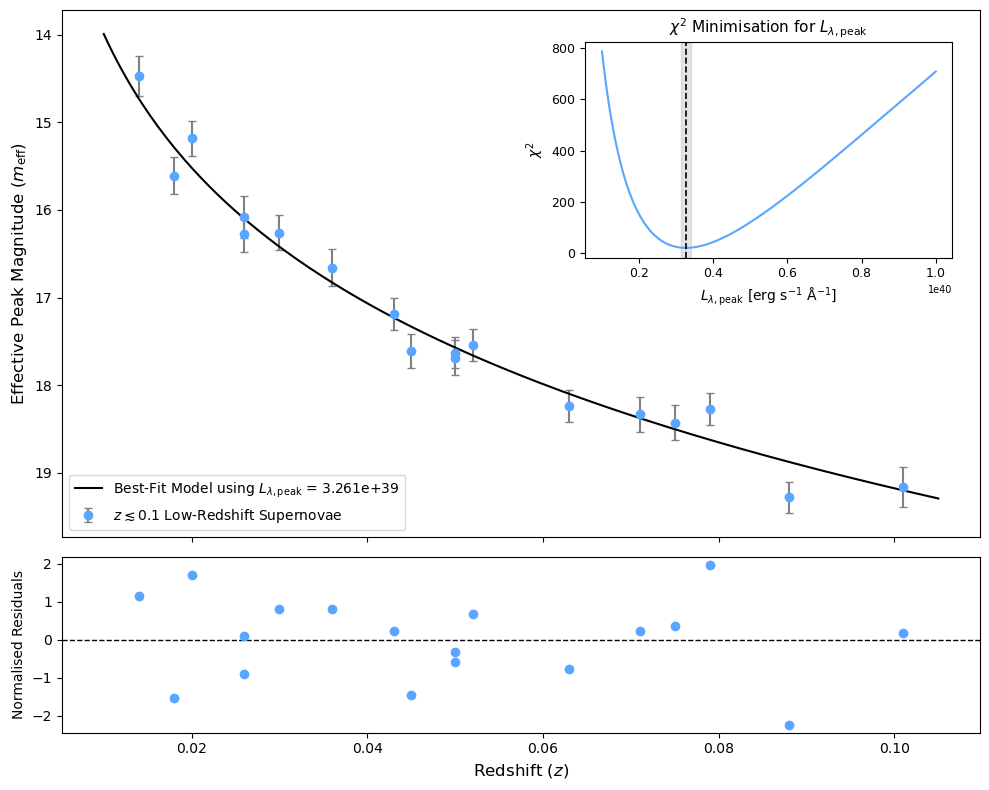

In [11]:
# Plot the Low-Redshift Supernova Data vs. Approximation Model with Normalised Residual Plot and Chi-Squared Sub-plot

# Generate a smooth range of redshifts specifically for the low-redshift regime
z_low_smooth = np.linspace(0.01, 0.105, 200)

# Calculate the model magnitudes across these redshifts using the low-redshift approximation and best_Lpeak
model_magnitude_low_smooth = model_magnitude_low(z_low_smooth, best_Lpeak)

# Calculate the normalised residuals for the low-redshift data
residuals_low = (model_magnitude_low(z_low, best_Lpeak) - m_low) / dm_low

# Create a two-panel figure
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

# Plot low-redshift data points with error bars and the approximation model curve
ax1.errorbar(z_low, m_low, dm_low, fmt='o', color="#58A6FF", ecolor="gray", capsize=3, label=f'$z \lesssim 0.1$ Low-Redshift Supernovae')
ax1.plot(z_low_smooth, model_magnitude_low_smooth, color='black', linestyle='-', label=f'Best-Fit Model using $L_{{\\lambda,\\mathrm{{peak}}}}$ = {best_Lpeak:.3e}')

ax1.invert_yaxis()
ax1.set_ylabel(r"Effective Peak Magnitude ($m_{\mathrm{eff}}$)", fontsize=12)
ax1.legend(fontsize=10, loc='lower left')

# Add the Lpeak chi-squared minimisation plot in the upper-right corner
ax_chi2 = ax1.inset_axes([0.57, 0.53, 0.40, 0.41])

ax_chi2.plot(Lpeak_grid, chi2_low_values, color="#58A6FF", linewidth=1.5)
ax_chi2.axvspan(L_low, L_high, color='black', alpha=0.1)
ax_chi2.axvline(best_Lpeak, color="black", linestyle="--", linewidth=1.2)

ax_chi2.set_title(r'$\chi^2$ Minimisation for $L_{\lambda,\mathrm{peak}}$', fontsize=11)
ax_chi2.set_xlabel(r'$L_{\lambda,\mathrm{peak}}$ [erg s$^{-1}$ Å$^{-1}$]', fontsize=10)
ax_chi2.set_ylabel(r'$\chi^2$', fontsize=10)
ax_chi2.tick_params(axis='both', labelsize=9)
ax_chi2.ticklabel_format(axis='x', style='sci', scilimits=(0, 0))
ax_chi2.xaxis.get_offset_text().set_fontsize(7)

# Add normalised residual subplot for low-redshift data
ax2.errorbar(z_low, residuals_low, fmt='o', color="#58A6FF", ecolor="gray", capsize=3)
ax2.axhline(0, color='black', linestyle='--', linewidth=1)
ax2.set_xlabel(f"Redshift ($z$)", fontsize=12)
ax2.set_ylabel("Normalised Residuals", fontsize=10)

plt.tight_layout()
plt.show()

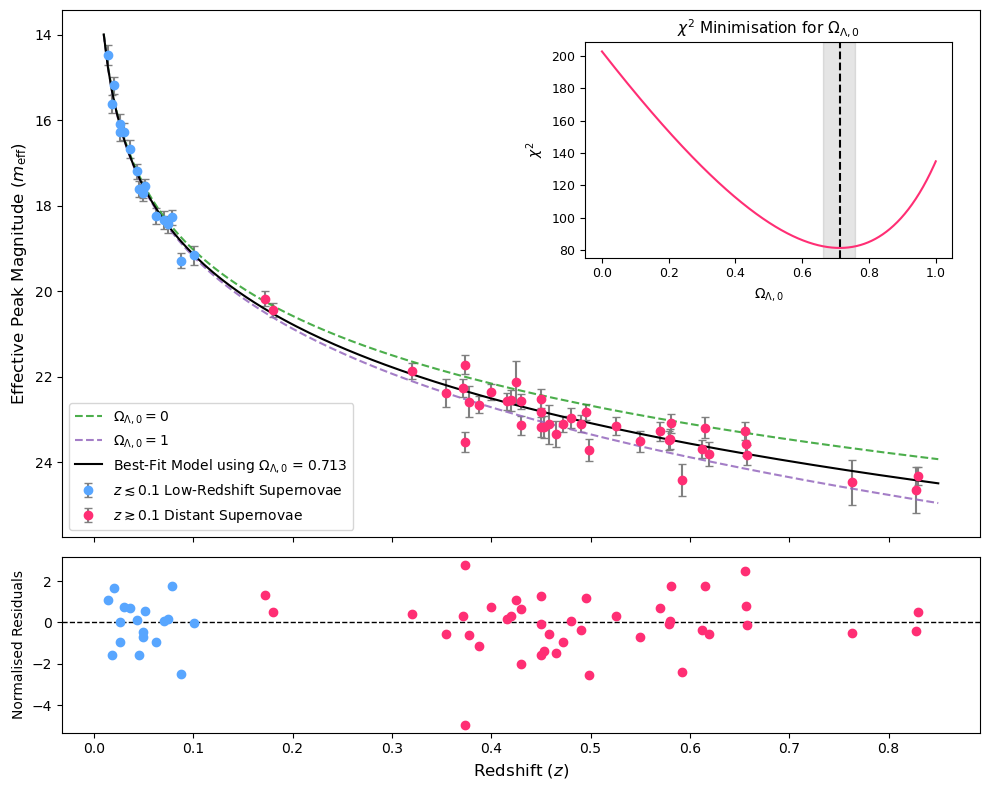

In [12]:
# Plot the Supernova Data vs. Best-Fit Model with Normalised Residual Plot and Chi-Squared Sub-plot

# Generate a smooth range of redshifts for the model curve
z_smooth = np.linspace(0.01, 0.85, 200)

# Calculate the model magnitudes across these redshifts using the best-fit parameters
model_magnitude_smooth = model_magnitude(z_smooth, best_Lpeak, H0, best_OM, best_OL)

# Calculate models for Omega Lambda = 0 and Omega Lambda = 1
model_OL0 = model_magnitude(z_smooth, best_Lpeak, H0, 1, 0)
model_OL1 = model_magnitude(z_smooth, best_Lpeak, H0, 0, 1)

# Calculate the normalised residuals for the best-fit model
residuals_low = (model_magnitude(z_low, best_Lpeak, H0, best_OM, best_OL) - m_low) / dm_low
residuals_high = (model_magnitude(z_high, best_Lpeak, H0, best_OM, best_OL) - m_high) / dm_high

# Create a two-panel figure
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

# Plot data points with error bars and model curves
ax1.errorbar(z_low, m_low, dm_low, fmt='o', color="#58A6FF", ecolor="gray", capsize=3, label=f'$z \lesssim 0.1$ Low-Redshift Supernovae')
ax1.errorbar(z_high, m_high, dm_high, fmt='o', color="#FF2E74", ecolor="gray", capsize=3, label=f'$z \gtrsim 0.1$ Distant Supernovae')

ax1.plot(z_smooth, model_OL0, color='#2CA02C', linestyle='--', linewidth=1.5, alpha=0.85, label=r'$\Omega_{\Lambda,0} = 0$')
ax1.plot(z_smooth, model_OL1, color='#9467BD', linestyle='--', linewidth=1.5, alpha=0.85, label=r'$\Omega_{\Lambda,0} = 1$')
ax1.plot(z_smooth, model_magnitude_smooth, color='black', linestyle='-', label=f'Best-Fit Model using $\\Omega_{{\\Lambda,0}}$ = {best_OL:.3f}')

ax1.invert_yaxis()
ax1.set_ylabel(r"Effective Peak Magnitude ($m_{\mathrm{eff}}$)", fontsize=12)
ax1.legend(fontsize=10, loc='lower left')

# Add the Omega Lambda chi-squared minimisation plot in the upper-right corner
ax_chi2 = ax1.inset_axes([0.57, 0.53, 0.40, 0.41])

ax_chi2.plot(OL_grid, chi2_high_values, color="#FF2E74", linewidth=1.5)
ax_chi2.axvspan(OL_low, OL_high, color='black', alpha=0.1)
ax_chi2.axvline(best_OL, color="black", linestyle="--", linewidth=1.5)

ax_chi2.set_title(r'$\chi^2$ Minimisation for $\Omega_{\Lambda,0}$', fontsize=11)
ax_chi2.set_xlabel(r'$\Omega_{\Lambda,0}$', fontsize=10)
ax_chi2.set_ylabel(r'$\chi^2$', fontsize=10)
ax_chi2.tick_params(axis='both', labelsize=9)

# Add normalised residual subplot
ax2.errorbar(z_low, residuals_low, fmt='o', color="#58A6FF")
ax2.errorbar(z_high, residuals_high, fmt='o', color="#FF2E74")
ax2.axhline(0, color='black', linestyle='--', linewidth=1)
ax2.set_xlabel(f"Redshift ($z$)", fontsize=12)
ax2.set_ylabel("Normalised Residuals", fontsize=10)
ax2.xaxis.set_major_locator(ticker.MultipleLocator(0.1))

plt.tight_layout()
plt.show()